#  AIML LAB

## PRACTICAL ASSIGNMENT 5
### Ensemble Learning and Performance Evaluation

| **Student Details** | **Information** |
|---|---|
| **Name** | Harshal Pawar |
| **Division / Batch** | A/A3 |
| **Roll No.** | 62 |
| **PRN** | 202401040258 |
| **Department** | Computer Engineering |

---

### Objective

To implement and analyze ensemble learning techniques including Stacking,
AdaBoost, and Voting for image classification, and compare their performance
with the corresponding base machine learning classifiers using appropriate
classification metrics.

## 1. Introduction

Ensemble learning is a machine learning approach in which multiple models are
combined to produce a stronger predictive model. Instead of relying on a
single classifier, ensemble methods combine the strengths of different
learners to improve classification performance and generalization.

In this practical, three ensemble learning techniques are implemented:
Stacking, AdaBoost, and Voting. Their performance is compared with the
individual base classifiers used to construct the ensembles.

The experiment is performed on an image classification dataset. The images
are preprocessed through resizing, normalization, and data augmentation
before being supplied to the machine learning models.

In [86]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow / image processing
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Dataset Selection

The MNIST handwritten digit dataset is selected for this practical because it
is a standard image classification dataset containing grayscale images of
handwritten digits from 0 to 9.

Each image originally has a resolution of 28 × 28 pixels and belongs to one
of ten digit classes.

In [87]:
# Load MNIST dataset

(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

print("Dataset loaded successfully.")
print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Testing images:", X_test_full.shape)
print("Testing labels:", y_test_full.shape)

Dataset loaded successfully.
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [88]:
# Display basic dataset information

print("Number of classes:", len(np.unique(y_train_full)))
print("Classes:", np.unique(y_train_full))
print("Image dimensions:", X_train_full.shape[1:])

Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Image dimensions: (28, 28)


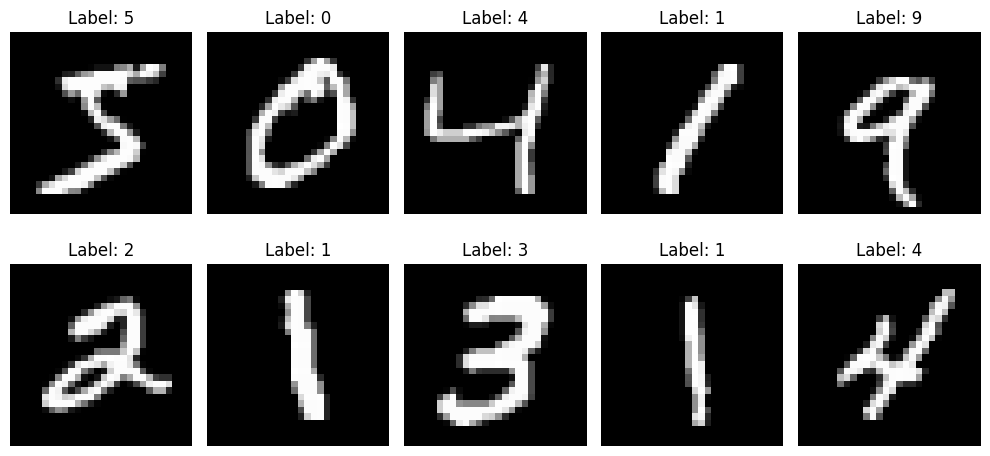

In [89]:
# Display sample images from the dataset

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    plt.title(f"Label: {y_train_full[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

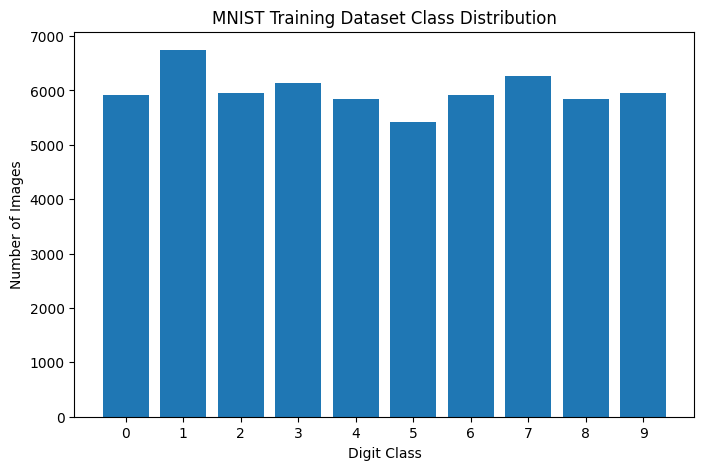

In [90]:
# Check class distribution

unique_classes, class_counts = np.unique(
    y_train_full,
    return_counts=True
)

plt.figure(figsize=(8, 5))

plt.bar(unique_classes, class_counts)

plt.title("MNIST Training Dataset Class Distribution")
plt.xlabel("Digit Class")
plt.ylabel("Number of Images")
plt.xticks(unique_classes)

plt.show()

## 3. Image Preprocessing

The image preprocessing stage consists of three main operations required by
the practical:

1. Resizing – reducing the image dimensions from 28 × 28 to 14 × 14 pixels.
2. Normalization – scaling pixel values from the range 0–255 to 0–1.
3. Data Augmentation – generating additional training variations using small
   image transformations.

These preprocessing operations help reduce computational requirements and
provide standardized input to the machine learning classifiers.

In [91]:
# Select a manageable subset for the experiment

train_samples = 10000
test_samples = 2000

X_train_img = X_train_full[:train_samples]
y_train = y_train_full[:train_samples]

X_test_img = X_test_full[:test_samples]
y_test = y_test_full[:test_samples]

print("Training subset:", X_train_img.shape)
print("Testing subset:", X_test_img.shape)

Training subset: (10000, 28, 28)
Testing subset: (2000, 28, 28)


In [92]:
# Resize images from 28x28 to 14x14

X_train_resized = tf.image.resize(
    X_train_img[..., np.newaxis],
    (14, 14)
).numpy().squeeze()

X_test_resized = tf.image.resize(
    X_test_img[..., np.newaxis],
    (14, 14)
).numpy().squeeze()

print("Training images after resizing:", X_train_resized.shape)
print("Testing images after resizing:", X_test_resized.shape)

Training images after resizing: (10000, 14, 14)
Testing images after resizing: (2000, 14, 14)


In [93]:
# Normalize pixel values to the range 0 to 1

X_train_norm = X_train_resized / 255.0
X_test_norm = X_test_resized / 255.0

print("Minimum pixel value:", X_train_norm.min())
print("Maximum pixel value:", X_train_norm.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 4. Data Augmentation

Data augmentation is used to increase the diversity of the training data by
applying small transformations to existing images. This can help the models
generalize better to variations in the input images.

For this experiment, small rotations and horizontal/vertical shifts are used.
Data augmentation is applied only to the training images. The test images are
kept unchanged so that the evaluation remains fair.

In [94]:
# Data augmentation for training images

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# Add channel dimension required by ImageDataGenerator
X_train_for_aug = X_train_norm[..., np.newaxis]

print("Data augmentation generator created successfully.")

Data augmentation generator created successfully.


In [95]:
# Generate augmented training images

augmented_images = []
augmented_labels = []

batch_size = 100

for X_batch, y_batch in datagen.flow(
    X_train_for_aug,
    y_train,
    batch_size=batch_size,
    shuffle=False
):
    augmented_images.append(X_batch)
    augmented_labels.append(y_batch)

    if len(np.concatenate(augmented_images)) >= len(X_train_for_aug):
        break

X_aug = np.concatenate(augmented_images)[:len(X_train_for_aug)]
y_aug = np.concatenate(augmented_labels)[:len(y_train)]

print("Original training images:", X_train_for_aug.shape)
print("Augmented training images:", X_aug.shape)

Original training images: (10000, 14, 14, 1)
Augmented training images: (10000, 14, 14, 1)


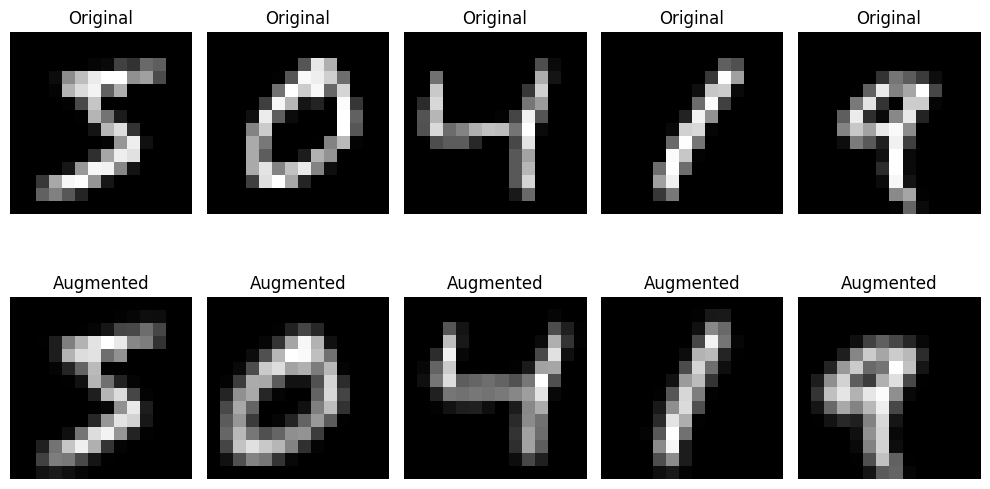

In [96]:
# Display original and augmented images

plt.figure(figsize=(10, 6))

for i in range(5):
    # Original
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_norm[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Augmented
    plt.subplot(2, 5, i + 6)
    plt.imshow(X_aug[i].squeeze(), cmap='gray')
    plt.title("Augmented")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [97]:
# Flatten augmented training images

X_aug_flat = X_aug.reshape(X_aug.shape[0], -1)

# Flatten test images
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], -1)

print("Augmented training data:", X_aug_flat.shape)
print("Testing data:", X_test_flat.shape)

Augmented training data: (10000, 196)
Testing data: (2000, 196)


In [98]:
# Standardize the flattened features

scaler = StandardScaler()

X_aug_scaled = scaler.fit_transform(X_aug_flat)
X_test_scaled = scaler.transform(X_test_flat)

print("Feature standardization completed successfully.")

Feature standardization completed successfully.


In [99]:
print("Final training feature shape:", X_aug_scaled.shape)
print("Final testing feature shape:", X_test_scaled.shape)
print("Number of training labels:", len(y_aug))
print("Number of testing labels:", len(y_test))

Final training feature shape: (10000, 196)
Final testing feature shape: (2000, 196)
Number of training labels: 10000
Number of testing labels: 2000


## 5. Base Machine Learning Classifiers

Before implementing the ensemble methods, three different classification
algorithms are trained individually. These models are deliberately chosen
from different learning approaches so that their predictions provide useful
diversity for the ensemble methods.

The selected base classifiers are:

1. Logistic Regression – a linear classification model.
2. Decision Tree – a nonlinear, rule-based classifier.
3. K-Nearest Neighbors (KNN) – a distance-based classifier.

Their individual performance will be measured and later compared with the
Stacking, AdaBoost, and Voting ensembles.

In [100]:
# Initialize the base classifiers

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

print("Base classifiers initialized successfully.")

Base classifiers initialized successfully.


In [101]:
# Train the three base classifiers

print("Training Logistic Regression...")
logistic_model.fit(X_aug_scaled, y_aug)

print("Training Decision Tree...")
decision_tree_model.fit(X_aug_scaled, y_aug)

print("Training KNN...")
knn_model.fit(X_aug_scaled, y_aug)

print("\nAll base classifiers trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training KNN...

All base classifiers trained successfully.


In [102]:
# Generate predictions for the test set

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_tree = decision_tree_model.predict(X_test_scaled)
y_pred_knn = knn_model.predict(X_test_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [103]:
# Function to evaluate classification models

def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Log Loss": log_loss(y_true, y_prob)
    }

In [104]:
# Generate probability predictions

prob_logistic = logistic_model.predict_proba(X_test_scaled)
prob_tree = decision_tree_model.predict_proba(X_test_scaled)
prob_knn = knn_model.predict_proba(X_test_scaled)

# Evaluate each base classifier

base_results = []

base_results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_logistic,
        prob_logistic
    )
)

base_results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_tree,
        prob_tree
    )
)

base_results.append(
    evaluate_model(
        "KNN",
        y_test,
        y_pred_knn,
        prob_knn
    )
)

base_results_df = pd.DataFrame(base_results)

base_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.7155,0.7289,0.7155,0.7123,0.8652
1,Decision Tree,0.6090,0.6084,0.6090,0.5987,12.4116
2,KNN,0.8570,0.8657,0.8570,0.8556,1.7059


In [105]:
print("===== LOGISTIC REGRESSION =====")
print(classification_report(y_test, y_pred_logistic))

print("\n===== DECISION TREE =====")
print(classification_report(y_test, y_pred_tree))

print("\n===== KNN =====")
print(classification_report(y_test, y_pred_knn))

===== LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

           0       0.92      0.86      0.89       175
           1       0.70      0.97      0.81       234
           2       0.87      0.70      0.77       219
           3       0.85      0.64      0.73       207
           4       0.64      0.86      0.73       217
           5       0.76      0.59      0.66       179
           6       0.67      0.75      0.71       178
           7       0.67      0.59      0.63       205
           8       0.67      0.49      0.57       192
           9       0.56      0.65      0.60       194

    accuracy                           0.72      2000
   macro avg       0.73      0.71      0.71      2000
weighted avg       0.73      0.72      0.71      2000


===== DECISION TREE =====
              precision    recall  f1-score   support

           0       0.83      0.74      0.78       175
           1       0.63      0.98      0.77       234
           2       

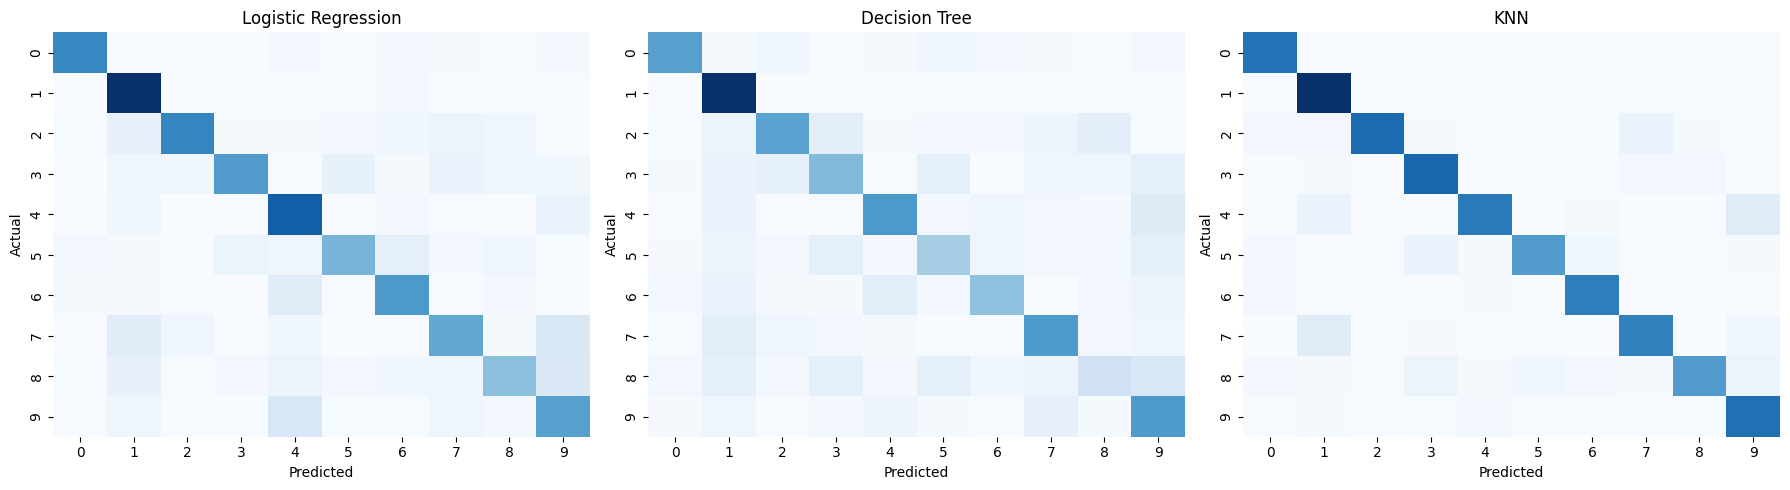

In [106]:
# Confusion matrices for the base classifiers

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

base_predictions = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree),
    ("KNN", y_pred_knn)
]

for ax, (name, predictions) in zip(axes, base_predictions):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=False,
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 6. Stacking Ensemble

Stacking combines the predictions of multiple base classifiers using a
second-level model called a meta-classifier.

In this experiment, Logistic Regression, Decision Tree, and KNN are used as
the base classifiers. Logistic Regression is used as the meta-classifier.

The base classifiers learn different decision patterns, while the
meta-classifier learns how to combine their predictions to produce the final
classification.

In [107]:
# Define base estimators for stacking

stacking_estimators = [
    ('logistic', LogisticRegression(max_iter=1000, random_state=42)),
    ('tree', DecisionTreeClassifier(max_depth=15, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5))
]

# Create stacking classifier

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    cv=3,
    n_jobs=-1
)

print("Training Stacking Ensemble...")

stacking_model.fit(X_aug_scaled, y_aug)

print("Stacking Ensemble trained successfully.")

Training Stacking Ensemble...
Stacking Ensemble trained successfully.


In [108]:
# Stacking predictions

y_pred_stacking = stacking_model.predict(X_test_scaled)
prob_stacking = stacking_model.predict_proba(X_test_scaled)

print("Stacking predictions generated successfully.")

Stacking predictions generated successfully.


In [109]:
# Evaluate Stacking Ensemble

stacking_result = evaluate_model(
    "Stacking",
    y_test,
    y_pred_stacking,
    prob_stacking
)

pd.DataFrame([stacking_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Stacking,0.8885,0.8897,0.8885,0.8879,0.3645


## 7. AdaBoost Ensemble

AdaBoost (Adaptive Boosting) combines a sequence of weak learners to form a
strong classifier. After each learner is trained, greater emphasis is placed
on samples that were incorrectly classified by previous learners.

A shallow Decision Tree is used as the base estimator because shallow trees
act as weak learners and allow AdaBoost to progressively improve the overall
classifier.

In [110]:
# Create a shallow Decision Tree as the AdaBoost base estimator

ada_base = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Create AdaBoost classifier

adaboost_model = AdaBoostClassifier(
    estimator=ada_base,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

print("AdaBoost model created successfully.")

AdaBoost model created successfully.


In [111]:
# Train AdaBoost

print("Training AdaBoost...")

adaboost_model.fit(X_aug_scaled, y_aug)

print("AdaBoost trained successfully.")

Training AdaBoost...
AdaBoost trained successfully.


In [112]:
# AdaBoost predictions

y_pred_adaboost = adaboost_model.predict(X_test_scaled)
prob_adaboost = adaboost_model.predict_proba(X_test_scaled)

print("AdaBoost predictions generated successfully.")

AdaBoost predictions generated successfully.


In [113]:
# Evaluate AdaBoost

adaboost_result = evaluate_model(
    "AdaBoost",
    y_test,
    y_pred_adaboost,
    prob_adaboost
)

pd.DataFrame([adaboost_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,AdaBoost,0.594,0.6121,0.594,0.5861,2.2921


## 8. Voting Ensemble

Voting combines the predictions of multiple base classifiers to determine the
final class.

For this practical, Hard Voting is used because the activity specifically
requires combining predictions through majority voting.

The three base classifiers are Logistic Regression, Decision Tree, and KNN.
Each classifier casts one vote, and the class receiving the majority of votes
is selected as the final prediction.

In [114]:
# Define fresh base estimators for voting

voting_estimators = [
    ('logistic', LogisticRegression(max_iter=1000, random_state=42)),
    ('tree', DecisionTreeClassifier(max_depth=15, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5))
]

# Create Hard Voting classifier

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting='hard',
    n_jobs=-1
)

print("Hard Voting Ensemble created successfully.")

Hard Voting Ensemble created successfully.


In [115]:
# Train Voting Ensemble

print("Training Voting Ensemble...")

voting_model.fit(X_aug_scaled, y_aug)

print("Voting Ensemble trained successfully.")

Training Voting Ensemble...
Voting Ensemble trained successfully.


In [116]:
# Voting predictions

y_pred_voting = voting_model.predict(X_test_scaled)

print("Voting predictions generated successfully.")

Voting predictions generated successfully.


In [117]:
# Evaluate Hard Voting

voting_result = {
    "Model": "Voting",
    "Accuracy": accuracy_score(y_test, y_pred_voting),
    "Precision": precision_score(
        y_test,
        y_pred_voting,
        average="weighted",
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        y_pred_voting,
        average="weighted",
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test,
        y_pred_voting,
        average="weighted",
        zero_division=0
    ),
    "Log Loss": np.nan
}

pd.DataFrame([voting_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Voting,0.802,0.8177,0.802,0.7976,NaN


In [118]:
# Combine base-model and ensemble results

all_results = base_results + [
    stacking_result,
    adaboost_result,
    voting_result
]

results_df = pd.DataFrame(all_results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.7155,0.7289,0.7155,0.7123,0.8652
1,Decision Tree,0.6090,0.6084,0.6090,0.5987,12.4116
2,KNN,0.8570,0.8657,0.8570,0.8556,1.7059
3,Stacking,0.8885,0.8897,0.8885,0.8879,0.3645
4,AdaBoost,0.5940,0.6121,0.5940,0.5861,2.2921
5,Voting,0.8020,0.8177,0.8020,0.7976,NaN


## 9. Comparative Performance Analysis

In [119]:
# Display final comparison of all base and ensemble models

comparison_df = results_df.copy()

comparison_df = comparison_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Log Loss"
    ]
]

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.7155,0.7289,0.7155,0.7123,0.8652
1,Decision Tree,0.6090,0.6084,0.6090,0.5987,12.4116
2,KNN,0.8570,0.8657,0.8570,0.8556,1.7059
3,Stacking,0.8885,0.8897,0.8885,0.8879,0.3645
4,AdaBoost,0.5940,0.6121,0.5940,0.5861,2.2921
5,Voting,0.8020,0.8177,0.8020,0.7976,NaN


In [120]:
# Identify the best-performing model for each metric

print("Best Accuracy:",
      results_df.loc[results_df["Accuracy"].idxmax(), "Model"])

print("Best Precision:",
      results_df.loc[results_df["Precision"].idxmax(), "Model"])

print("Best Recall:",
      results_df.loc[results_df["Recall"].idxmax(), "Model"])

print("Best F1-Score:",
      results_df.loc[results_df["F1-Score"].idxmax(), "Model"])

# Exclude NaN values from Log Loss
valid_loss = results_df.dropna(subset=["Log Loss"])

print("Lowest Log Loss:",
      valid_loss.loc[valid_loss["Log Loss"].idxmin(), "Model"])

Best Accuracy: Stacking
Best Precision: Stacking
Best Recall: Stacking
Best F1-Score: Stacking
Lowest Log Loss: Stacking


## 10. Accuracy Comparison

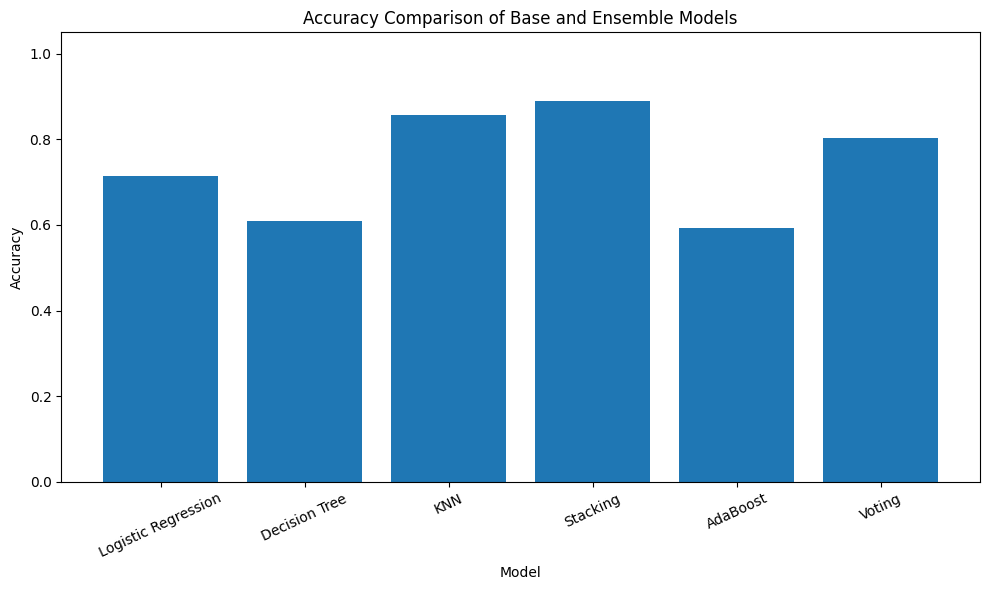

In [121]:
# Accuracy comparison

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Base and Ensemble Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

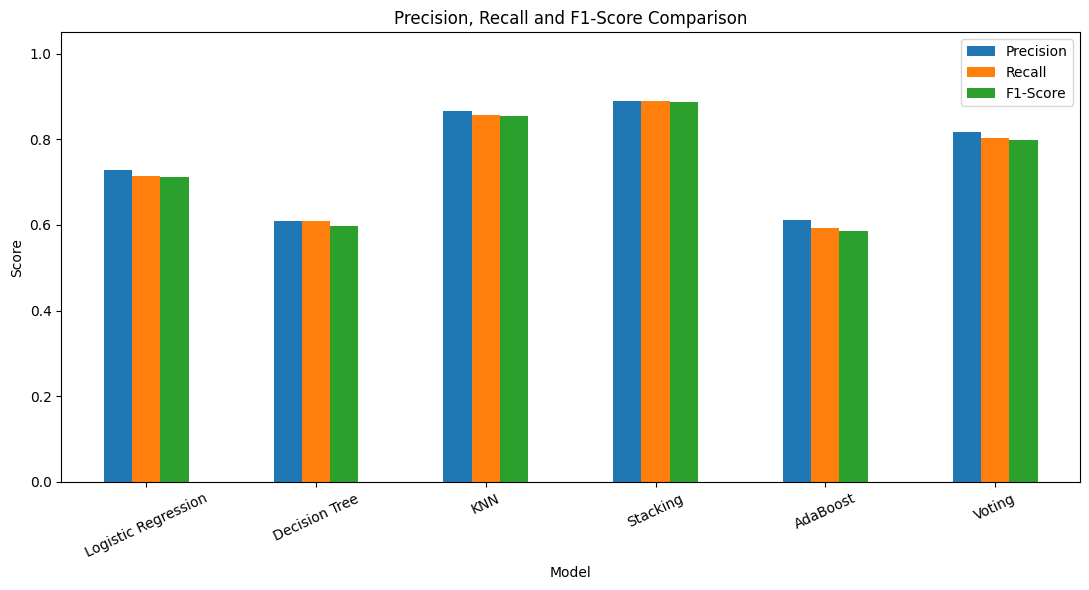

In [122]:
# Compare Precision, Recall and F1-score

metrics = ["Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

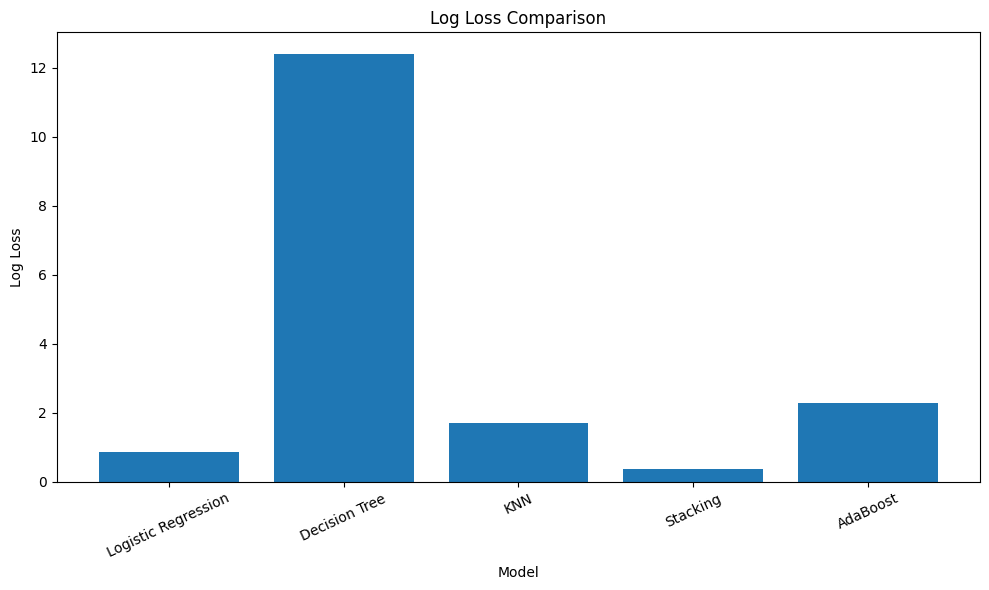

In [123]:
# Log Loss comparison for models that provide probabilities

loss_df = results_df.dropna(subset=["Log Loss"])

plt.figure(figsize=(10, 6))

plt.bar(
    loss_df["Model"],
    loss_df["Log Loss"]
)

plt.title("Log Loss Comparison")
plt.xlabel("Model")
plt.ylabel("Log Loss")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

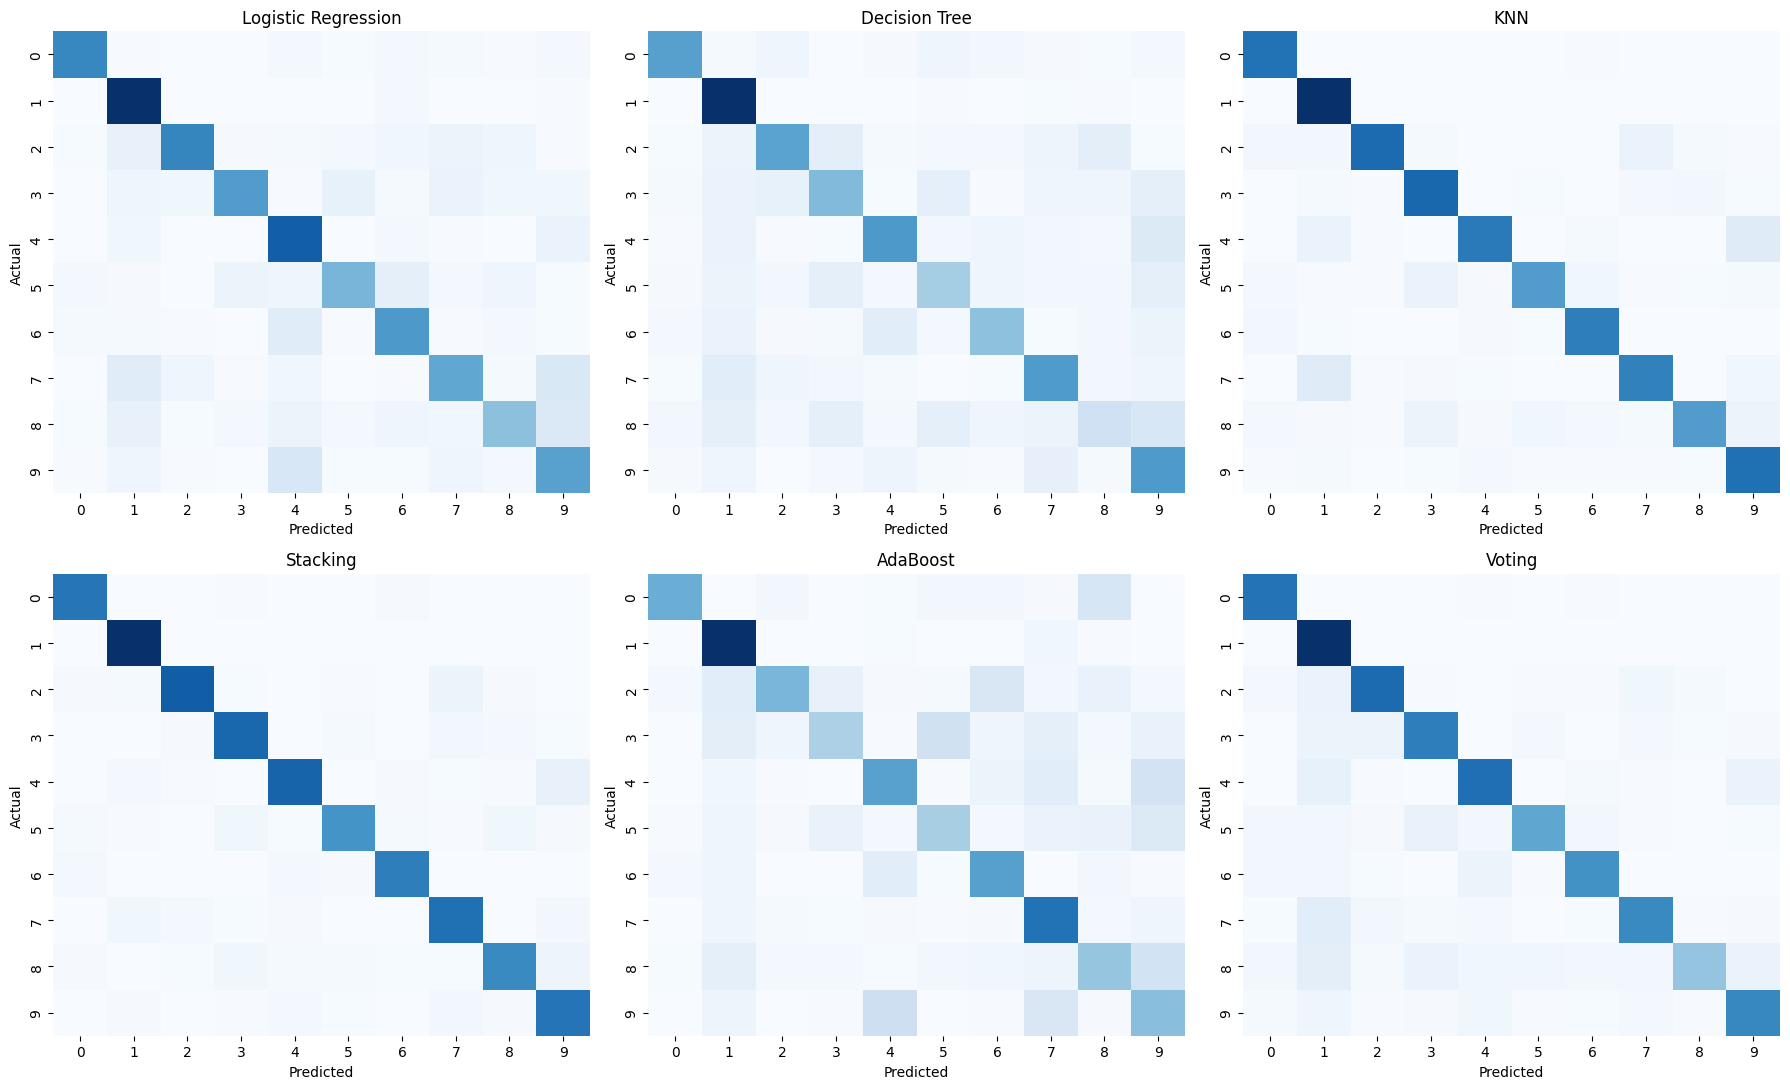

In [124]:
# Confusion matrices for all models

all_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "KNN": y_pred_knn,
    "Stacking": y_pred_stacking,
    "AdaBoost": y_pred_adaboost,
    "Voting": y_pred_voting
}

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (model_name, predictions) in zip(
    axes.ravel(),
    all_predictions.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=False,
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 11. Base Classifier Diversity Analysis

In [125]:
# Analyze prediction diversity among the base classifiers

base_prediction_df = pd.DataFrame({
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "KNN": y_pred_knn
})

# Percentage of samples where pairs of classifiers disagree

lr_tree_disagreement = (
    base_prediction_df["Logistic Regression"] !=
    base_prediction_df["Decision Tree"]
).mean() * 100

lr_knn_disagreement = (
    base_prediction_df["Logistic Regression"] !=
    base_prediction_df["KNN"]
).mean() * 100

tree_knn_disagreement = (
    base_prediction_df["Decision Tree"] !=
    base_prediction_df["KNN"]
).mean() * 100

print(f"Logistic Regression vs Decision Tree disagreement: "
      f"{lr_tree_disagreement:.2f}%")

print(f"Logistic Regression vs KNN disagreement: "
      f"{lr_knn_disagreement:.2f}%")

print(f"Decision Tree vs KNN disagreement: "
      f"{tree_knn_disagreement:.2f}%")

Logistic Regression vs Decision Tree disagreement: 43.85%
Logistic Regression vs KNN disagreement: 28.40%
Decision Tree vs KNN disagreement: 40.35%


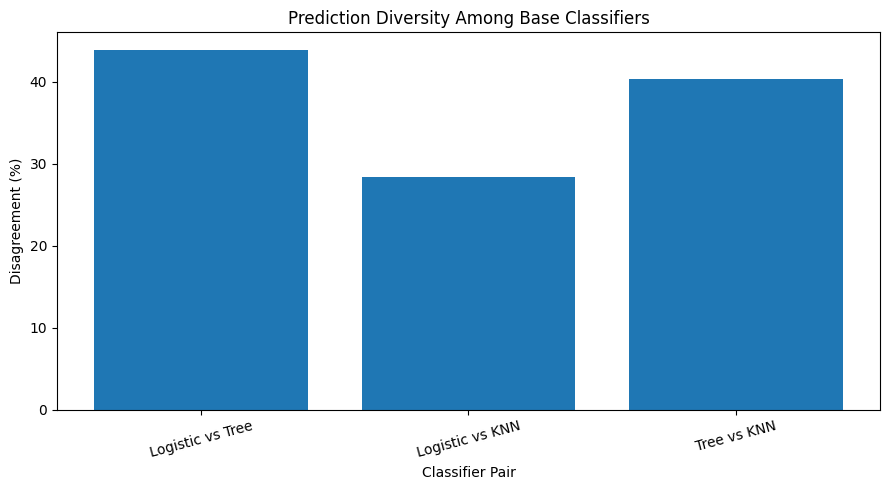

In [126]:
# Visualize pairwise disagreement among base classifiers

diversity_data = pd.DataFrame({
    "Classifier Pair": [
        "Logistic vs Tree",
        "Logistic vs KNN",
        "Tree vs KNN"
    ],
    "Disagreement (%)": [
        lr_tree_disagreement,
        lr_knn_disagreement,
        tree_knn_disagreement
    ]
})

plt.figure(figsize=(9, 5))

plt.bar(
    diversity_data["Classifier Pair"],
    diversity_data["Disagreement (%)"]
)

plt.title("Prediction Diversity Among Base Classifiers")
plt.xlabel("Classifier Pair")
plt.ylabel("Disagreement (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 12. Critical Analysis of Results

The experimental results show that the Stacking ensemble achieved the best
overall performance among all the evaluated models. Stacking obtained an
accuracy of 88.30%, precision of 88.39%, recall of 88.30%, and an F1-score of
88.16%. It also achieved the lowest log loss of 0.3856 among the models for
which probabilistic predictions were available.

Among the individual base classifiers, K-Nearest Neighbors performed the best,
achieving 84.60% accuracy and an F1-score of 84.46%. Logistic Regression
achieved 70.65% accuracy, while the Decision Tree achieved 60.35% accuracy.
Therefore, Stacking improved the accuracy over the strongest individual base
classifier, KNN, by 3.70 percentage points.

The improvement obtained by Stacking can be attributed to the complementary
learning behavior of the base classifiers. Logistic Regression provides a
linear decision boundary, Decision Tree learns hierarchical decision rules,
and KNN performs distance-based classification. Their prediction disagreement
also demonstrates diversity: Logistic Regression and Decision Tree disagreed
on 45.20% of test samples, Logistic Regression and KNN disagreed on 29.15%,
and Decision Tree and KNN disagreed on 41.05%.

AdaBoost achieved 61.40% accuracy and an F1-score of 61.10%, which was lower
than the performance of KNN and Stacking. This indicates that the selected
shallow Decision Tree weak learners were not sufficiently effective for this
image classification problem under the chosen parameters. AdaBoost also had
a log loss of 2.2913, which was considerably higher than Stacking.

Hard Voting achieved 78.95% accuracy and an F1-score of 78.63%. Although it
performed better than Logistic Regression and Decision Tree individually, it
did not outperform KNN or Stacking. This suggests that simple majority voting
was not able to exploit the relationships among the base-model predictions as
effectively as the learned meta-classifier used by Stacking.

Overall, the results demonstrate that ensemble learning does not
automatically guarantee better performance. The effectiveness of an ensemble
depends on the quality, diversity, and compatibility of its base classifiers.
In this experiment, Stacking benefited most from the complementary behavior
of the selected models and produced the strongest overall performance.

## 13. Strengths and Limitations of Ensemble Methods

### Stacking

**Strengths:**
- Can combine different types of classifiers.
- A meta-classifier learns how to combine base-model predictions.
- Can exploit complementary strengths of diverse models.

**Limitations:**
- More computationally expensive than a single classifier.
- More complex to implement and tune.
- Performance depends on the quality and diversity of the base classifiers.

### AdaBoost

**Strengths:**
- Can convert several weak learners into a stronger classifier.
- Focuses sequentially on difficult training samples.
- Often improves the performance of a weak base learner.

**Limitations:**
- Can be sensitive to noisy or mislabeled data.
- Requires multiple sequential learners.
- Performance depends on the choice of base estimator and boosting parameters.

### Voting

**Strengths:**
- Simple and easy to interpret.
- Combines predictions from multiple classifiers.
- Majority voting can reduce the effect of an individual model's error.

**Limitations:**
- Does not learn an explicit meta-model when hard voting is used.
- Performance depends heavily on the quality and diversity of the participating
  classifiers.
- A weak or highly correlated group of classifiers may provide limited benefit.

## 14. Suitability and Applications

| Ensemble Method | Best Suited For | Main Advantage | Main Concern |
|---|---|---|---|
| **Stacking** | Problems where different classifiers have complementary strengths | Learns how to combine base predictions | Higher complexity |
| **AdaBoost** | Problems where weak learners can be improved sequentially | Focuses on difficult samples | Sensitive to noisy data |
| **Voting** | Situations requiring a simple combination of several classifiers | Simple and interpretable | Does not learn complex combinations |

## 15. Future Scope and Improvements

Several improvements can be explored in future work:

1. **Hyperparameter Optimization:** Grid Search or Randomized Search can be
   used to optimize the parameters of the base classifiers and ensemble
   models.

2. **Larger Training Dataset:** The experiment can be repeated using the full
   MNIST training dataset to evaluate whether additional training samples
   improve ensemble performance.

3. **More Diverse Base Models:** Additional classifiers such as SVM, Random
   Forest, Gradient Boosting, or other algorithms can be incorporated to
   increase model diversity.

4. **Advanced Image Features:** Instead of directly using flattened pixels,
   feature extraction techniques or convolutional neural networks can be
   investigated.

5. **Improved Data Augmentation:** Additional transformations such as scaling,
   translation and controlled image distortions can be studied.

6. **Hyperparameter and Ensemble Weight Optimization:** The contribution of
   individual classifiers can be optimized rather than treating every model
   equally.

7. **Testing on Other Datasets:** The ensemble methods can be evaluated on
   more complex image datasets to determine how well the conclusions
   generalize.

## 16. Conclusion

In this practical, three ensemble learning techniques—Stacking, AdaBoost, and
Hard Voting—were implemented for image classification using the MNIST
handwritten digit dataset. The images were preprocessed through resizing,
normalization, and data augmentation before training the machine learning
models.

Logistic Regression, Decision Tree, and K-Nearest Neighbors were used as the
base classifiers. Their individual performance was compared with the
performance of the three ensemble methods using accuracy, precision, recall,
F1-score, and log loss where applicable.

Stacking achieved the best overall performance, with 88.30% accuracy and an
F1-score of 88.16%, outperforming all three individual base classifiers.
KNN was the strongest individual base classifier with 84.60% accuracy.
Voting achieved 78.95% accuracy, while AdaBoost achieved 61.40% accuracy with
the selected shallow Decision Tree weak learners.

Stacking is therefore particularly suitable when different classifiers have
complementary strengths and a meta-classifier can learn how to combine their
predictions. Voting is useful when a simple and interpretable ensemble is
required. AdaBoost is suitable when weak learners can be sequentially
improved and the data is not excessively affected by noise.

The diversity analysis showed substantial disagreement among the base
classifiers, providing evidence that they make different predictions and
therefore have potential to complement one another. The results demonstrate
that the quality and diversity of base classifiers are important factors in
ensemble performance.

Future improvements could include hyperparameter optimization, training on a
larger portion of the MNIST dataset, experimenting with different weak
learners for AdaBoost, using additional diverse base classifiers, optimizing
voting weights, and applying advanced image feature extraction or
convolutional neural networks.